In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
%matplotlib inline

In [23]:
import scipy.odr as odr


#

## Calibrations

### Task 6.2.2 [2 absorbers with different temperatures]

In [25]:
def func_straight_line(x, m, c):
    """
    """
    return m*np.asarray(x) + c # = y


#### 2nd attempt values

In [3]:
T_absorber_hot = 22.5 + 273.15 # convert Celsius to Kelvin
errT_absorber_hot = 0.5 # convert Celsius to Kelvin
T_absorber_cold = 1.5 + 273.15 # convert Celsius to Kelvin
errT_absorber_cold = 0.5 # convert Celsius to Kelvin

P_cold_task622 = 42_006
errP_cold_task622 = 186
P_hot_task622 = 42_783
errP_hot_task622 = 105


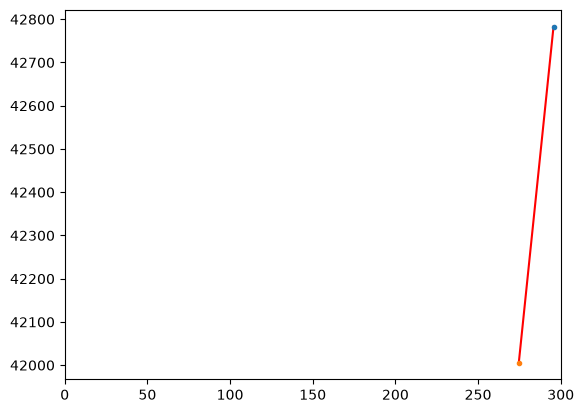

In [4]:
plt.plot(np.array([T_absorber_cold, T_absorber_hot]), np.array([P_cold_task622, P_hot_task622]), 'r-')

plt.plot(T_absorber_hot, P_hot_task622, '.')
plt.plot(T_absorber_cold, P_cold_task622, '.')

#plt.ylim(0, 43_000)
plt.xlim(0, 300);


$P_{absorber} = \alpha_{max}(T_{absober} + T_{sys}) = \alpha_{max}T_{absorber} + (\alpha_{max}T_{sys})$    
$y = mx + c$     
=> $m=\alpha_{max} = \frac{y_2-y_1}{x_2-x_1} = \frac{P_{absorber,hot}-P_{absorber,cold}}{T_{absorber,hot}-T_{absorber,cold}}$

In [5]:
print( (P_hot_task622-P_cold_task622)/(T_absorber_cold-T_absorber_hot) )

-37.0


$c = (\alpha_{max}T_{sys})$ => $T_{sys} = \frac{c}{\alpha_{max}} = \frac{c}{m}$

In [6]:
pars_task622, cov_task622 = curve_fit(func_straight_line, xdata=np.array([T_absorber_cold, T_absorber_hot]), ydata=np.array([P_cold_task622, P_hot_task622])) 
            # will have to give uncertainties
# popt, pcov = curve_fit(function, xdata, ydata, sigma=yerr, absolute_sigma=True, p0=initial_pars)

#pars contains the fitted parameters
# => for fitfunc used here, pars[0] = m (slope) & pars[1] = c (intercept)
#cov = the covariance matrix & can be used to get the error on the slope & intercept
# => for fitfunc used here, np.sqrt(cov[0,0]) = err_slope & np.sqrt(cov[1,1]) = err_intercept
print(pars_task622[0], pars_task622[1])

36.99999999999996 31843.95000000001


C:\Users\cathe\AppData\Local\Temp\ipykernel_17772\4071669496.py:1: OptimizeWarning: Covariance of the parameters could not be estimated
  pars_task622, cov_task622 = curve_fit(func_straight_line, xdata=np.array([T_absorber_cold, T_absorber_hot]), ydata=np.array([P_cold_task622, P_hot_task622]))


In [7]:
print(pars_task622[1]/pars_task622[0]) # T_sys = c/m


860.6472972972986


#### Final attempt values

In [8]:
task622_T_abs_array = np.array([28.0, -3.5]) +273.15 # to convert from Celsius to Kelvin # in order of: hot, cold
task622_errT_array = np.array([0.5, 0.5]) # hot, cold

task622_P_array = np.array([45_868, 43_435]) # hot, cold
task622_errP_array = np.array([171, 139]) # hot, cold


In [14]:
### ROUGH LOOK AT WHAT T_SYS COULD BE:
pars_task622, cov_task622 = curve_fit(func_straight_line, task622_T_abs_array, task622_P_array, sigma=task622_errP_array, absolute_sigma=True) 
            # will have to give uncertainties
# popt, pcov = curve_fit(function, xdata, ydata, sigma=yerr, absolute_sigma=True, p0=initial_pars)

#pars contains the fitted parameters
# => for fitfunc used here, pars[0] = m (slope) & pars[1] = c (intercept)
#cov = the covariance matrix & can be used to get the error on the slope & intercept
# => for fitfunc used here, np.sqrt(cov[0,0]) = err_slope & np.sqrt(cov[1,1]) = err_intercept
print(pars_task622[0], pars_task622[1]) # m, c
print('\n', pars_task622[1]/pars_task622[0]) # T_sys = c/m

77.2380952380954 22607.74761904757

 292.70203452527625


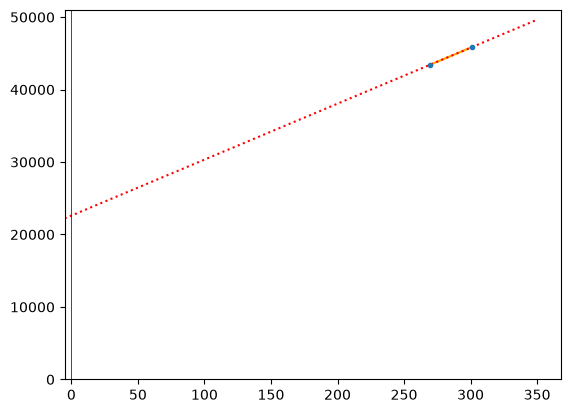

In [20]:
plt.plot(task622_T_abs_array, task622_P_array, color='orange')
plt.errorbar(task622_T_abs_array, task622_P_array, yerr=task622_errP_array, xerr=task622_errT_array, fmt='.', zorder=10);

testX_plotting = np.linspace(-5, 350, 100)
plt.plot(testX_plotting, pars_task622[0]*testX_plotting + pars_task622[1], 'r:') # y=mx+c

plt.ylim(0)
plt.axvline(0, color='k', linewidth=0.5)
plt.xlim(np.min(testX_plotting));

In [ ]:
# have to fit a line with error bars in *both* directions [error propagation is *not sufficient)

In [24]:
     # trying scipy's ODR
task622_data = odr.RealData(task622_T_abs_array, task622_P_array, sx=task622_errT_array, sy=task622_errP_array) # x, y, err_x, err_y

In [30]:
# 
def func_model_straight_line(p, x):
    m, c = p
    return m * x + c

task622_model = odr.Model(func_model_straight_line) # func_straight_line)#

In [35]:
# p_odr = scipy.odr.ODR(p_dat, p_mod, beta0=[1., 1.])
task622_odr = odr.ODR(task622_data, task622_model, beta0=[pars_task622[0], pars_task622[1]]) # have to give some sort of initial param.s

task622_odr_output = task622_odr.run()
task622_odr_output.pprint() # fitting a straight line to only 2 points, so not really a surprise that m&c parameters = as w/curve_fit

Beta: [   77.23809524 22607.74761905]
Beta Std Error: [1.56384310e-28 4.42241585e-26]
Beta Covariance: [[ 5.19474512e+01 -1.46683428e+04]
 [-1.46683428e+04  4.15429223e+06]]
Residual Variance: 4.707844525982228e-58
Inverse Condition #: 0.027104004940435255
Reason(s) for Halting:
  Parameter convergence


In [39]:
task622_odr_output.beta[1]/task622_odr_output.beta[0] # T_sys = c/m
## still need the final, overall uncertainties [Can we do error propagation here or not???]

np.float64(292.70203452527795)